In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# 1. Random sample + histogram
# R: r <- rnorm(n=1000, mean=0, sd=1); hist(r, col="red")

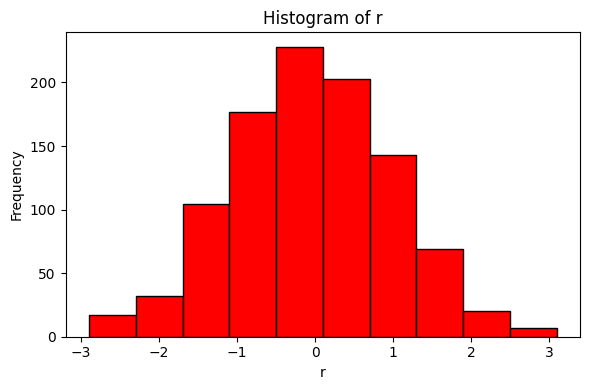

In [10]:
r = np.random.normal(loc=0, scale=1, size=1000)

plt.figure(figsize=(6, 4))
plt.hist(r, color="red", edgecolor="black")
plt.title("Histogram of r")
plt.xlabel("r")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 2. Arithmetic expressions and standard calculations

In [11]:
print(2 + 2)               # 4
print(np.exp(-2))          # 0.1353353
print(np.pi)                # 3.141593
print(np.cos(np.pi / 3))   # 0.5


4
0.1353352832366127
3.141592653589793
0.5000000000000001


# 3. Assignments
# R: x <- 2; y <- 3; x + y

In [12]:
x = 2
y = 3
print(x + y)  # 5

5


# 4. Vector
# R: Nifty.50 <- c(8114.30, 7965.50, 8033.30, 8002.30, 7929.10)

In [13]:
Nifty_50_vec = np.array([8114.30, 7965.50, 8033.30, 8002.30, 7929.10])
print(Nifty_50_vec)

[8114.3 7965.5 8033.3 8002.3 7929.1]


# 5. Download stock price data from Yahoo Finance

In [14]:
data = yf.download(
    "^NSEI",
    start="2016-11-21",
    end="2016-11-26",
    auto_adjust=False,
)
Nifty_50 = data["Adj Close"].squeeze()  # ensure 1-D Series, not a 1-col DataFrame
print(Nifty_50)


[*********************100%***********************]  1 of 1 completed

Date
2016-11-21    7929.100098
2016-11-22    8002.299805
2016-11-23    8033.299805
2016-11-24    7965.500000
2016-11-25    8114.299805
Name: ^NSEI, dtype: float64


In [15]:
# 6. Compute log-return
# R: ln_rt <- diff(log(Nifty.50))

ln_rt = np.log(Nifty_50).diff().dropna()
ln_rt.name = "ln_rt"
print(ln_rt)


# 7. Compute simple return
# R: Rt <- exp(ln_rt) - 1

Rt = np.exp(ln_rt) - 1
print(Rt)
print(Rt * 100)
print(ln_rt * 100)

# 8. Average return
# R: mean(ln_rt)

print(ln_rt.mean())


# 9. Volatility (standard deviation)
# R: sd(ln_rt) * 100
# Note: R's sd() divides by (n-1), same as pandas' default .std(ddof=1),
# so this matches exactly.

daily_vol = ln_rt.std() * 100
print(daily_vol)
print("Daily volatility: Nifty 50 can move up/down by "
      f"{float(daily_vol):.5f}% on a given day.")


# 10. Monthly and yearly volatility (square-root-of-time scaling)
# R:
#   sqrt(22)*sd(ln_rt)*100   -> monthly  (≈22 trading days/month)
#   sqrt(252)*sd(ln_rt)*100  -> yearly   (≈252 trading days/year)

monthly_vol = np.sqrt(22) * ln_rt.std() * 100
yearly_vol = np.sqrt(252) * ln_rt.std() * 100
print(monthly_vol)
print(yearly_vol)

Date
2016-11-22    0.009189
2016-11-23    0.003866
2016-11-24   -0.008476
2016-11-25    0.018508
Name: ln_rt, dtype: float64
Date
2016-11-22    0.009232
2016-11-23    0.003874
2016-11-24   -0.008440
2016-11-25    0.018681
Name: ln_rt, dtype: float64
Date
2016-11-22    0.923178
2016-11-23    0.387389
2016-11-24   -0.843984
2016-11-25    1.868054
Name: ln_rt, dtype: float64
Date
2016-11-22    0.918943
2016-11-23    0.386640
2016-11-24   -0.847566
2016-11-25    1.850820
Name: ln_rt, dtype: float64
0.005772091176415195
1.126227783932981
Daily volatility: Nifty 50 can move up/down by 1.12623% on a given day.
5.282476546910271
17.87831181538832


"""
Geometric Brownian Motion (GBM)

Original R code used:
    library(tseries); library(zoo)
    FTSE <- EuStockMarkets[,"FTSE"]
    ... GBM parameter estimation ...
    ... rnorm() simulation of log-returns ...
    ... plot of historical + simulated path ...

Theory:
    P_T = P_0 * exp[(mu - sigma^2/2)*T + sigma*W_T],   W_T ~ N(0, T)

    Log-return over Δt:
        r_i = log(P_{i+1}) - log(P_i) = (mu - sigma^2/2)*Δt + sigma*sqrt(Δt)*Z,  Z ~ N(0,1)

    Method-of-moments estimators (with Δt = 1, daily step as used in the workshop):
        r_bar = sample mean of log-returns
        s^2   = sample variance of log-returns   (ddof=1, i.e. R's default sd())

        mu_hat    ≈ r_bar + s^2 / 2
        sigma_hat ≈ s / sqrt(Δt)
"""
# 1. Load the data
#    R's EuStockMarkets is a built-in dataset (daily closing prices, 1991-1998,
#    of DAX, SMI, CAC, FTSE). Python has no built-in copy, so we pull the same
#    dataset from the public Rdatasets mirror on GitHub.

n (historical obs.)   : 1860
r_bar                  : 0.000432
s (sigma_hat)          : 0.007958
mu_hat                 : 0.000464


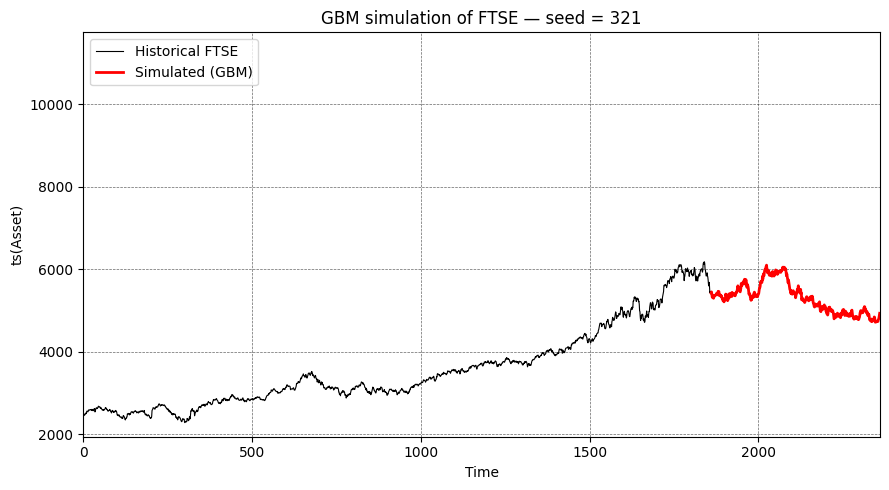

In [ ]:
DATA_URL = (
    "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/"
    "master/csv/datasets/EuStockMarkets.csv"
)

euro_stocks = pd.read_csv(DATA_URL)
Asset = euro_stocks["FTSE"].to_numpy()        # equivalent of: FTSE <- EuStockMarkets[,"FTSE"]; Asset <- FTSE

# 2. GBM parameter estimation from historical log-returns

sim_size = 500
n = len(Asset)

rt = np.diff(np.log(Asset))      # log-returns: log(P_{i+1}) - log(P_i)
rbar = rt.mean()
s = rt.std(ddof=1)               # ddof=1 -> matches R's sd() (sample std, denominator n-1)

delta_t = 1
mu_hat = rbar + s**2 / 2         # drift estimate
sigma_hat = s / np.sqrt(delta_t) # volatility estimate

print(f"n (historical obs.)   : {n}")
print(f"r_bar                  : {rbar:.6f}")
print(f"s (sigma_hat)          : {s:.6f}")
print(f"mu_hat                 : {mu_hat:.6f}")


def simulate_gbm_path(asset, mu_hat, sigma_hat, sim_size, seed):
    """
    Simulate a forward GBM price path by drawing log-returns and compounding them,
    exactly mirroring the R loop:
        rt.sim   <- rnorm(sim.size, mean=(mu_hat - s^2/2), sd=s)
        Asset.sim[1] <- Asset[n]*exp(rt.sim[1])
        for(i in 2:sim.size) Asset.sim[i] <- Asset.sim[i-1]*exp(rt.sim[i])
    """
    rng = np.random.default_rng(seed)
    rt_sim = rng.normal(loc=(mu_hat - sigma_hat**2 / 2), scale=sigma_hat, size=sim_size)

    asset_sim = np.empty(sim_size)
    asset_sim[0] = asset[-1] * np.exp(rt_sim[0])
    for i in range(1, sim_size):
        asset_sim[i] = asset_sim[i - 1] * np.exp(rt_sim[i])

    return asset_sim



# 3. Simulate and plot (this matches the R block with set.seed(321))

def plot_gbm(asset, asset_sim, n, sim_size, seed, ax=None):
    yl = asset.min() * 0.85
    yu = asset.max() * 1.9

    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 5))

    ax.plot(np.arange(n), asset, color="black", linewidth=0.8, label="Historical FTSE")
    ax.plot(np.arange(n, n + sim_size), asset_sim, color="red", linewidth=2, label="Simulated (GBM)")
    ax.set_xlim(0, n + sim_size)
    ax.set_ylim(yl, yu)
    ax.set_xlabel("Time")
    ax.set_ylabel("ts(Asset)")
    ax.set_title(f"GBM simulation of FTSE — seed = {seed}")
    ax.grid(color="black", linewidth=0.5, linestyle="--", alpha=0.6)
    ax.legend(loc="upper left")
    return ax


if __name__ == "__main__":
    SEED = 321  
                #     "Change the value of the seed and see
                #     how the plot changes!!"

    asset_sim = simulate_gbm_path(Asset, mu_hat, sigma_hat, sim_size, seed=SEED)
    plot_gbm(Asset, asset_sim, n, sim_size, seed=SEED)
    plt.tight_layout()
    plt.savefig("gbm_ftse_seed321.png", dpi=150)
    plt.show()